In [1]:
# ============================================================
# 1. KONFIGURASI
# ============================================================
import copy
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)
 
from model import build_model   # model.py harus satu folder dengan file ini
 
DATA_DIR   = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split')
TRAIN_CSV  = DATA_DIR / 'data_train.csv'
VAL_CSV    = DATA_DIR / 'data_val.csv'
TEST_CSV   = DATA_DIR / 'data_test.csv'
 
TARGET     = '_michd'
DROP_COLS  = ['iyear']
STATE_COL  = '_state'
 
DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EPOCHS     = 50
BATCH_SIZE = 64
LR         = 1e-3
PATIENCE   = 5
SEEDS      = [42, 0, 123, 1337, 3407]     # 5 seed berbeda
 
METRIK = ['acc', 'prec', 'rec', 'f1', 'auc', 'prauc']
NAMA   = {'acc': 'Akurasi', 'prec': 'Presisi', 'rec': 'Recall',
          'f1': 'F1-score', 'auc': 'AUC', 'prauc': 'PR-AUC'}
 
print("Device:", DEVICE, "| Seeds:", SEEDS)
 
# %%
# ============================================================
# 2. MUAT DATA
# ============================================================
df_train = pd.read_csv(TRAIN_CSV)
df_val   = pd.read_csv(VAL_CSV)
df_test  = pd.read_csv(TEST_CSV)
 
for nama, d in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f"{nama:<5}: {d.shape}")
 
if TARGET not in df_train.columns:
    raise KeyError(f"Kolom target '{TARGET}' tidak ada. Kolom tersedia:\n{list(df_train.columns)}")
 
for nama, d in [('train', df_train), ('val', df_val), ('test', df_test)]:
    if d[TARGET].isna().any():
        raise ValueError(f"Target di {nama} mengandung NaN.")
    nilai = set(d[TARGET].unique())
    if not nilai <= {0, 1}:
        raise ValueError(f"Target di {nama} harus 0/1, ditemukan: {sorted(nilai)}. "
                         f"Petakan dulu (mis. 1->1, 2->0).")
 
state_test = df_test[STATE_COL].values if STATE_COL and STATE_COL in df_test.columns else None
 
drop = [c for c in DROP_COLS + ([STATE_COL] if STATE_COL else []) if c in df_train.columns]
feature_cols = [c for c in df_train.columns if c != TARGET and c not in drop]
 
non_num = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df_train[c])]
if non_num:
    print("PERINGATAN - kolom non-numerik dibuang:", non_num)
    feature_cols = [c for c in feature_cols if c not in non_num]
 
print(f"\nTarget       : {TARGET}")
print(f"Jumlah fitur : {len(feature_cols)}")

Device: cuda | Seeds: [42, 0, 123, 1337, 3407]
train: (59971, 72)
val  : (35679, 72)
test : (29368, 72)

Target       : _michd
Jumlah fitur : 69


In [2]:

# ============================================================
# 3. PRAPROSES (imputasi median & scaling HANYA dari data train)
# ============================================================
median = df_train[feature_cols].median().fillna(0.0)
 
 
def prep(d):
    X = d[feature_cols].fillna(median).values.astype(np.float32)
    y = d[TARGET].values.astype(np.int64)
    return X, y
 
 
X_train, y_train = prep(df_train)
X_val,   y_val   = prep(df_val)
X_test,  y_test  = prep(df_test)
 
scaler  = StandardScaler().fit(X_train)
X_train = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
X_val   = torch.tensor(scaler.transform(X_val),   dtype=torch.float32)
X_test  = torch.tensor(scaler.transform(X_test),  dtype=torch.float32)
y_train, y_val, y_test = (torch.tensor(a, dtype=torch.long) for a in (y_train, y_val, y_test))
 
assert not torch.isnan(X_train).any(), "X_train masih mengandung NaN"
 
ringkas = pd.DataFrame({
    'n':       [len(y_train), len(y_val), len(y_test)],
    'positif': [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
}, index=['train', 'val', 'test'])
ringkas['positif_%'] = (100 * ringkas['positif'] / ringkas['n']).round(2)
print("\nRingkasan data:")
print(ringkas.to_string())
 
# %%
# ============================================================
# 4. FUNGSI TRAIN & EVALUASI (seed sebagai argumen)
# ============================================================
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
 
 
def make_loader(X, y, shuffle, seed):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(TensorDataset(X.float(), y.long()),
                      batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)
 
 
@torch.no_grad()
def predict_logits(model, X, bs=4096):
    model.eval()
    out = [model(X[i:i + bs].float().to(DEVICE)) for i in range(0, len(X), bs)]
    return torch.cat(out)
 
 
@torch.no_grad()
def evaluate(model, X, y, criterion=None):
    logits = predict_logits(model, X)
    prob = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
    pred = logits.argmax(dim=1).cpu().numpy()
    y_np = y.long().cpu().numpy()
    dua_kelas = len(np.unique(y_np)) > 1
 
    out = {
        'acc':   accuracy_score(y_np, pred),
        'prec':  precision_score(y_np, pred, zero_division=0),
        'rec':   recall_score(y_np, pred, zero_division=0),
        'f1':    f1_score(y_np, pred, zero_division=0),
        'auc':   roc_auc_score(y_np, prob) if dua_kelas else np.nan,
        'prauc': average_precision_score(y_np, prob) if dua_kelas else np.nan,
    }
    if criterion is not None:
        out['loss'] = criterion(logits, y.long().to(DEVICE)).item()
    return out, pred, prob
 
 
def train_local(X_train, y_train, X_val, y_val, seed, verbose=False):
    set_seed(seed)
    model = build_model(in_dim=X_train.shape[1], seed=seed).to(DEVICE)
 
    n_pos = int(y_train.sum())
    n_neg = len(y_train) - n_pos
    if n_pos > 0 and n_neg > 0:
        w = torch.tensor([len(y_train) / (2 * n_neg),
                          len(y_train) / (2 * n_pos)], dtype=torch.float32)
    else:
        w = torch.ones(2)
    criterion = nn.CrossEntropyLoss(weight=w.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loader    = make_loader(X_train, y_train, shuffle=True, seed=seed)
 
    best_loss, best_state, wait = float('inf'), None, 0
    history = []
 
    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(loader.dataset)
 
        val, _, _ = evaluate(model, X_val, y_val, criterion)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'val_loss': val['loss'], 'val_f1': val['f1'],
                        'val_prauc': val['prauc']})
        if verbose:
            print(f"  ep {epoch:02d} | train {train_loss:.4f} | "
                  f"val {val['loss']:.4f} | val_f1 {val['f1']:.4f}")
 
        if val['loss'] < best_loss - 1e-5:
            best_loss, wait = val['loss'], 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break
 
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)
 
 
def metrik_per_state(y_np, pred, prob, states):
    rows = []
    for st in np.unique(states):
        m = states == st
        dua = len(np.unique(y_np[m])) > 1
        rows.append({
            'state':  st,
            'n_test': int(m.sum()),
            'pos_%':  100 * y_np[m].mean(),
            'acc':    accuracy_score(y_np[m], pred[m]),
            'prec':   precision_score(y_np[m], pred[m], zero_division=0),
            'rec':    recall_score(y_np[m], pred[m], zero_division=0),
            'f1':     f1_score(y_np[m], pred[m], zero_division=0),
            'auc':    roc_auc_score(y_np[m], prob[m]) if dua else np.nan,
            'prauc':  average_precision_score(y_np[m], prob[m]) if dua else np.nan,
        })
    return pd.DataFrame(rows).set_index('state')


Ringkasan data:
           n  positif  positif_%
train  59971    12705      21.19
val    35679     7816      21.91
test   29368     6143      20.92


seed 42    | ep 07 | VAL f1 0.4923 prauc 0.4631 | TEST f1 0.4716 prauc 0.4525 auc 0.7523
seed 0     | ep 08 | VAL f1 0.4909 prauc 0.4603 | TEST f1 0.4707 prauc 0.4511 auc 0.7516
seed 123   | ep 07 | VAL f1 0.4889 prauc 0.4609 | TEST f1 0.4676 prauc 0.4525 auc 0.7520
seed 1337  | ep 07 | VAL f1 0.4955 prauc 0.4597 | TEST f1 0.4771 prauc 0.4537 auc 0.7528
seed 3407  | ep 08 | VAL f1 0.4910 prauc 0.4586 | TEST f1 0.4722 prauc 0.4541 auc 0.7529

=== Hasil TEST per seed ===
         acc    prec     rec      f1     auc   prauc  epochs_run
seed                                                            
42    0.6530  0.3460  0.7404  0.4716  0.7523  0.4525           7
0     0.6588  0.3484  0.7254  0.4707  0.7516  0.4511           8
123   0.6375  0.3375  0.7612  0.4676  0.7520  0.4525           7
1337  0.6721  0.3579  0.7150  0.4771  0.7528  0.4537           7
3407  0.6530  0.3463  0.7423  0.4722  0.7529  0.4541           8

=== TEST (mean ± std, 5 seed) ===
Akurasi  : 0.6549 ± 0.0125
Presisi  

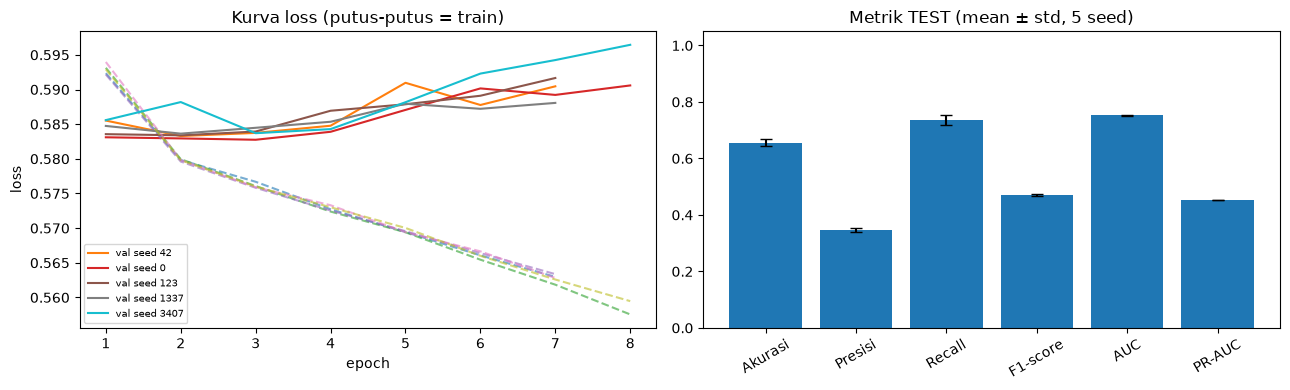

=== Kinerja per state (TEST, mean & std antar 5 seed) ===
       n_test  pos_%  acc_mean  prec_mean  rec_mean  f1_mean  auc_mean  prauc_mean  acc_std  prec_std  rec_std  f1_std  auc_std  prauc_std
state                                                                                                                                     
13.0      622  24.28    0.6949     0.4321    0.8132   0.5642    0.8030      0.5619   0.0124    0.0114   0.0190  0.0094   0.0043     0.0106
5.0       544  27.02    0.6500     0.4203    0.7769   0.5454    0.7496      0.4997   0.0104    0.0087   0.0112  0.0075   0.0033     0.0096
54.0      545  26.97    0.6492     0.4177    0.7578   0.5383    0.7431      0.5509   0.0163    0.0130   0.0141  0.0089   0.0048     0.0111
39.0      973  23.84    0.6403     0.3798    0.8034   0.5157    0.7697      0.5085   0.0059    0.0041   0.0267  0.0074   0.0030     0.0061
23.0      996  25.20    0.6275     0.3836    0.7857   0.5154    0.7419      0.4861   0.0136    0.0089   0.01

In [3]:

# %%
# ============================================================
# 5. LATIH & EVALUASI UNTUK 5 SEED
# ============================================================
hasil_val, hasil_test, hists, cms, state_dfs = {}, {}, {}, [], []
y_test_np = y_test.numpy()
 
for seed in SEEDS:
    model, hist = train_local(X_train, y_train, X_val, y_val, seed)
    val_m, _, _ = evaluate(model, X_val, y_val)
    test_m, pred, prob = evaluate(model, X_test, y_test)
 
    hasil_val[seed], hasil_test[seed], hists[seed] = val_m, test_m, hist
    cms.append(confusion_matrix(y_test_np, pred, labels=[0, 1]))
    if state_test is not None:
        state_dfs.append(metrik_per_state(y_test_np, pred, prob, state_test).assign(seed=seed))
 
    print(f"seed {seed:<5} | ep {len(hist):02d} | "
          f"VAL f1 {val_m['f1']:.4f} prauc {val_m['prauc']:.4f} | "
          f"TEST f1 {test_m['f1']:.4f} prauc {test_m['prauc']:.4f} auc {test_m['auc']:.4f}")
 
df_val  = pd.DataFrame(hasil_val).T[METRIK];  df_val.index.name  = 'seed'
df_test = pd.DataFrame(hasil_test).T[METRIK]; df_test.index.name = 'seed'
df_test['epochs_run'] = [len(hists[s]) for s in SEEDS]
 
# %%
# ============================================================
# 6. HASIL TEST: PER SEED + MEAN ± STD
# ============================================================
print("\n=== Hasil TEST per seed ===")
print(df_test.round(4).to_string())
 
 
def mean_std(df):
    return pd.DataFrame({'mean': df[METRIK].mean(), 'std': df[METRIK].std(ddof=1)}).rename(index=NAMA)
 
 
ms_test, ms_val = mean_std(df_test), mean_std(df_val)
 
print("\n=== TEST (mean ± std, 5 seed) ===")
for k, r in ms_test.iterrows():
    print(f"{k:<9}: {r['mean']:.4f} ± {r['std']:.4f}")
 
banding = pd.DataFrame({'VAL': ms_val['mean'], 'TEST': ms_test['mean']})
banding['Gap (val-test)'] = banding['VAL'] - banding['TEST']
print("\n=== Perbandingan rata-rata VAL vs TEST ===")
print(banding.round(4).to_string())
 
cm_mean = np.mean(cms, axis=0)
print("\nConfusion matrix rata-rata 5 seed (baris=aktual, kolom=prediksi):")
print(pd.DataFrame(cm_mean.round(1), index=['aktual 0', 'aktual 1'],
                   columns=['pred 0', 'pred 1']).to_string())
 
# %%
# ============================================================
# 7. VISUALISASI
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for seed, h in hists.items():
    axes[0].plot(h['epoch'], h['train_loss'], '--', alpha=0.6)
    axes[0].plot(h['epoch'], h['val_loss'], label=f'val seed {seed}')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss')
axes[0].set_title('Kurva loss (putus-putus = train)'); axes[0].legend(fontsize=7)
 
axes[1].bar(ms_test.index, ms_test['mean'], yerr=ms_test['std'], capsize=4)
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_title('Metrik TEST (mean ± std, 5 seed)')
plt.tight_layout()
plt.show()
 
# %%
# ============================================================
# 8. EVALUASI PER STATE (mean ± std antar seed)
# ============================================================
if state_dfs:
    allst = pd.concat(state_dfs)
    kolom = ['acc', 'prec', 'rec', 'f1', 'auc', 'prauc']
    g = allst.groupby('state')
    per_state = pd.concat({
        'n_test': g['n_test'].first(),
        'pos_%':  g['pos_%'].first().round(2),
        **{f'{k}_mean': g[k].mean() for k in kolom},
        **{f'{k}_std':  g[k].std(ddof=1) for k in kolom},
    }, axis=1).sort_values('f1_mean', ascending=False)
    print("=== Kinerja per state (TEST, mean & std antar 5 seed) ===")
    print(per_state.round(4).to_string())
else:
    print("STATE_COL kosong/tidak ada -> evaluasi per state dilewati.")
 
# Simpan (opsional)
# df_test.to_csv(DATA_DIR / 'metrik_test_5seed.csv')
# per_state.to_csv(DATA_DIR / 'metrik_per_state_5seed.csv')